In [1]:
import matplotlib.style as mplstyle
mplstyle.use('fast')
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from load_results import load, format
import matplotlib.pyplot as plt

import matplotlib.cm as cm
import numpy as np
import os
import pandas as pd
from sklearn.manifold import MDS
from scipy.linalg import orthogonal_procrustes
import math
import regex as re
import numpy as np
import numpy as np
import numpy as np
from adjustText import adjust_text
import pandas as pd
from load_results import format
df_predictability = pd.read_parquet("./results/rank_predictability_merged")



df_predictability = df_predictability.assign(
    score_name="pw_acc",
    score=df_predictability["acc"],
    k=-1,           
    normalize=False    
)[[
    "Experiment",
    "Rep_A",
    "Rep_B",
    "score_name",
    "score",
    "k",
    "normalize",
    "model",
    "train_dataset",
    "train_dataset_split",
    "test_dataset",
    "test_dataset_split",
    "selection_strategy_name_a",
    "selection_strategy_name_b"
]]




df_similarity = load()

df = pd.concat([df_predictability, df_similarity])

df = format(df)

In [2]:
scores_to_plot = [
    "pw_acc",
    "cka", 
    "spearman_rho"]

In [3]:

def rgba_to_hex(rgba):
    return '#{:02x}{:02x}{:02x}'.format(
        int(rgba[0]*255),
        int(rgba[1]*255),
        int(rgba[2]*255)
    )

def plot_mds_and_heatmaps(df, row_cols, col_col=None, save_dir="figures", main_fontsize=8, filter_fn=lambda df: df):
    os.makedirs(save_dir, exist_ok=True)
    for group_vals, df_setting in filter_fn(df).groupby(row_cols):
        if isinstance(group_vals, tuple):
            group_dict = dict(zip(row_cols, group_vals))
        else:
            group_dict = {row_cols[0]: group_vals}
        score_name = group_dict.get("score_name")
        if score_name not in scores_to_plot:
            continue
        nodes = sorted(pd.unique(df_setting[["Rep_A", "Rep_B"]].values.ravel()))
        idx = {n: i for i, n in enumerate(nodes)}
        n = len(nodes)
        cmap = plt.get_cmap("tab20", n)
        colors = {node: cmap(i) for i, node in enumerate(nodes)}

        if col_col is None:
            experiments = ["all"]
            grouped_experiments = [("all", df_setting)]
        else:
            experiments = df_setting[col_col].dropna().unique()
            grouped_experiments = list(df_setting.groupby(col_col))
            
            
        

        n_exp = len(experiments)
        max_cols = 4
        ncols = min(max_cols, n_exp)
        nrows = math.ceil(n_exp / ncols)
        square_size = 3
        
        filename_base = "_".join([col_col if col_col else "all"] + [f"{k}={v}" for k, v in group_dict.items()])
        filename_base = re.sub(r"[#$%&{}^~\\]", "", filename_base)
        filename_base = re.sub(r"[\s:/<>?|]+", "_", filename_base).lower()
        print(filename_base)
        

        fig_hm, axes_hm = plt.subplots(
            nrows, ncols,
            figsize=(square_size * ncols, square_size * nrows),
            squeeze=False,
            gridspec_kw={"wspace": 0.3, "hspace": 0.3},
        )
        axes_hm_flat = axes_hm.flatten()

        for ax, (exp, df_exp) in zip(axes_hm_flat, grouped_experiments):
            df_tmp = df_exp.copy()
            df_tmp[["Rep_A", "Rep_B"]] = np.sort(df_tmp[["Rep_A", "Rep_B"]], axis=1)
            df_agg = df_tmp.groupby(["Rep_A", "Rep_B"], as_index=False)["score"].mean()

            adj = np.full((n, n), np.nan)
            np.fill_diagonal(adj, 1.0)
            for _, r in df_agg.iterrows():
                i, j = idx[r["Rep_A"]], idx[r["Rep_B"]]
                adj[i, j] = adj[j, i] = r["score"]


            heatmap_data = pd.DataFrame(adj, index=nodes, columns=nodes)
            def fmt_custom(x):
                x_rounded = round(x, 2)
                if x_rounded == 0:
                    return ".00"
                if x_rounded == int(x_rounded):
                    s = str(int(x_rounded))
                else:
                    s = str(x_rounded)
                if s.startswith("0.") :
                    s = s[1:]
                
                return s
            sns.heatmap(
                heatmap_data,
                annot=True,
                cmap="viridis",
                vmin=0, vmax=1,
                square=True,
                cbar=False,
                ax=ax,
                annot_kws={"size": main_fontsize}
            )
            for t in ax.texts:
                val = float(t.get_text())
                t.set_text(fmt_custom(val))
           
            # # Now color each label individually
            for label in ax.get_xticklabels():
                node = label.get_text()
                label.set_color(rgba_to_hex(colors[node]))

            for label in ax.get_yticklabels():
                node = label.get_text()
                label.set_color(rgba_to_hex(colors[node]))
            if col_col:
                ax.set(title=exp.replace("_",""))
                ax.title.set_fontsize(main_fontsize+4)

        for ax in axes_hm_flat[len(grouped_experiments):]:
            ax.axis("off")
            
        
        plt.tight_layout()
        plt.savefig(
            os.path.join(save_dir, filename_base + "_heatmap.pgf"),
            format="pgf",
            bbox_inches="tight",
            pad_inches=0
        )
        plt.savefig(
            os.path.join(save_dir, filename_base + "_heatmap.png"),
            bbox_inches="tight",
            pad_inches=0
        )
        plt.show()
        
        # # -------------------------------
        # # First figure: MDS plots
        # # -------------------------------
        # fig_mds, axes_mds = plt.subplots(
        #     nrows, ncols,
        #     figsize=(square_size * ncols, square_size * nrows),
        #     squeeze=False,
        #     gridspec_kw={"wspace": 0, "hspace": 0},
        # )
        # axes_mds_flat = axes_mds.flatten()
        # ref_pos = None

        # for ax, (exp, df_exp) in zip(axes_mds_flat, grouped_experiments):
        #     df_tmp = df_exp.copy()
        #     df_tmp[["Rep_A", "Rep_B"]] = np.sort(df_tmp[["Rep_A", "Rep_B"]], axis=1)

        #     df_agg = df_tmp.groupby(["Rep_A", "Rep_B"], as_index=False)["score"].mean()

        #     adj = np.full((n, n), np.nan)
        #     np.fill_diagonal(adj, 1.0)
        #     for _, r in df_agg.iterrows():
        #         i, j = idx[r["Rep_A"]], idx[r["Rep_B"]]
        #         adj[i, j] = adj[j, i] = r["score"]
        #     #     #####################
        #     # nan_pairs = []
        #     # for i in range(n):
        #     #     for j in range(i+1, n):
        #     #         if np.isnan(adj[i, j]):
        #     #             nan_pairs.append((nodes[i], nodes[j]))
        #     # if len(nan_pairs):
        #     #     print("Missing pairs:")
        #     #     for a, b in nan_pairs:
        #     #         print(a, "<->", b)
        #     #     ######################
            
        #     if score_name in ["cka", "unbiased_cka"]:
        #         # cosine geometry
        #         dist = np.sqrt(np.clip(2 * (1 - adj), 0, None))

        #     elif score_name in ["spearman_rho"]:
        #         # correlation to angular distance
        #         dist = np.sqrt(np.clip(1 - adj, 0, None))
        #     elif score_name in [
        #         "cknna",
        #         "cycle_knn",
        #         "ndcg",
        #         "ndcg_k",
        #         "sign_agreement",
        #         "f1_at_k",
        #         "rbo"
        #     ]:
        #         # non-Euclidean similarities to dissimilarity
        #         dist = 1 - adj

        #     else:
        #         raise ValueError(f"[MDS] Unsupported or unknown score_name: {score_name}")

        #     np.fill_diagonal(dist, 0)
        #     # dist = np.nan_to_num(dist, nan=np.nanmax(dist) * 1.1)
        #     # print("[WARN] TODO nan are set to high dist")
        #     # MDS
            
        #     pos = MDS(n_components=2, dissimilarity="precomputed", random_state=42,n_init=1).fit_transform(dist)
        #     pos_centered = pos - pos.mean(axis=0)


        #     if ref_pos is None:
        #         ref_pos = pos_centered.copy()
        #         pos = pos_centered
        #     else:
        #         R, _ = orthogonal_procrustes(pos_centered, ref_pos)
        #         pos = pos_centered @ R

        #     sc = ax.scatter(pos[:, 0], pos[:, 1], c=[colors[n] for n in nodes], s=50)
        #     texts = []
            
        #     for i, node in enumerate(nodes):
        #         t = ax.annotate(
        #             node,
        #             xy=pos[i],
        #             # xytext=pos[i],
        #             xytext=(pos[i, 0] + 0.1, pos[i, 1] + 0.1),
        #             arrowprops=dict(
        #                 arrowstyle="->",
        #                 lw=0.8,
        #                 color=colors[node],
        #                 shrinkA=0,
        #                 shrinkB=0,
        #                 connectionstyle="arc3,rad=0.1",
        #             ),
        #             fontsize=main_fontsize+6,
        #             color=colors[node],
        #             clip_on=False,
        #         )
        #         texts.append(t)
            

        #     if col_col and False:
        #         ax.set(title=exp.replace("_",r""))
        #         ax.title.set_fontsize(main_fontsize)
            
        #     ax.set_xticks([])
        #     ax.set_yticks([])
        #     adjust_text(texts,add_objects=sc, ax=ax)
        # for ax in axes_mds_flat[len(grouped_experiments):]:
        #     ax.axis("off")

      
        
        # plt.tight_layout()
        # plt.savefig(
        #     os.path.join(save_dir, filename_base + "_mds.pgf"),
        #     format="pgf",
        #     bbox_inches="tight",
        #     pad_inches=0
        # )
        # plt.savefig(
        #     os.path.join(save_dir, filename_base + "_mds.png"),
        #     bbox_inches="tight",
        #     pad_inches=0
        # )
        plt.show()
        # break



most_influential
all_score_name=cka_k=-1_normalize=false


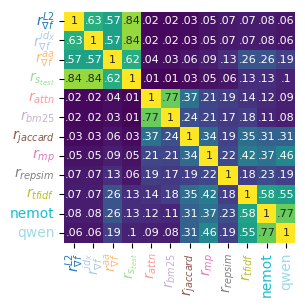

all_score_name=pw_acc_k=-1_normalize=false


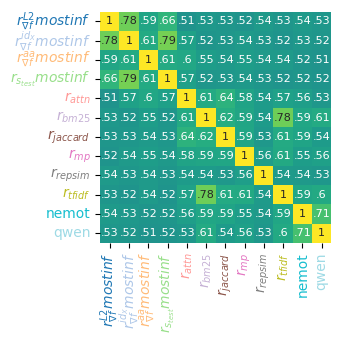

all_score_name=spearman_rho_k=-1_normalize=false


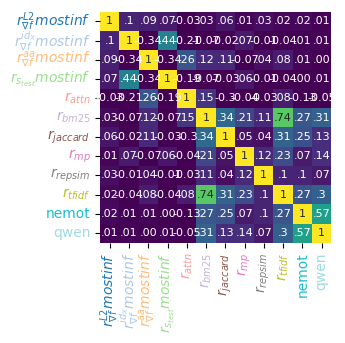

least_influential
all_score_name=cka_k=-1_normalize=false


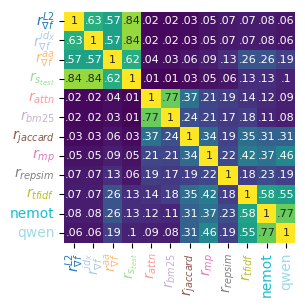

all_score_name=pw_acc_k=-1_normalize=false


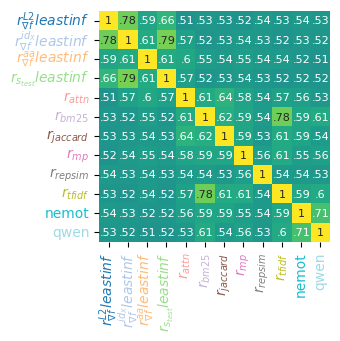

all_score_name=spearman_rho_k=-1_normalize=false


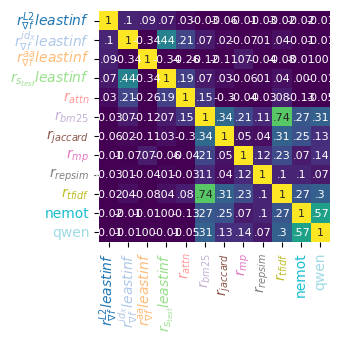

most_harmful
all_score_name=cka_k=-1_normalize=false


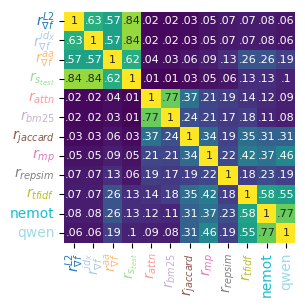

all_score_name=pw_acc_k=-1_normalize=false


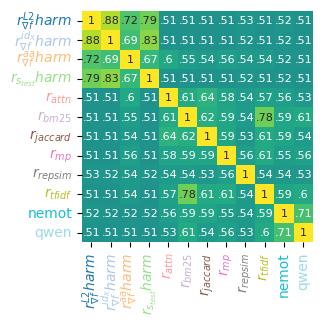

all_score_name=spearman_rho_k=-1_normalize=false


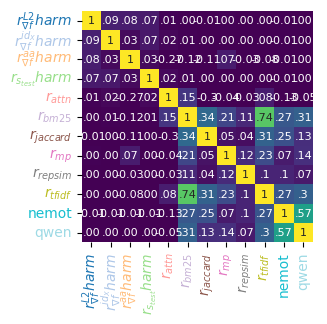

most_helpful
all_score_name=cka_k=-1_normalize=false


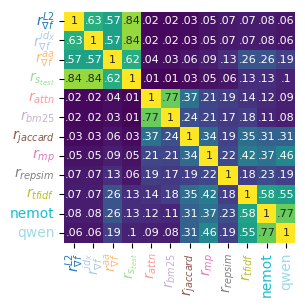

all_score_name=pw_acc_k=-1_normalize=false


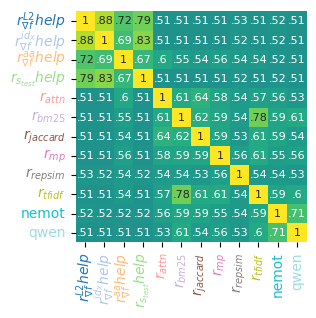

all_score_name=spearman_rho_k=-1_normalize=false


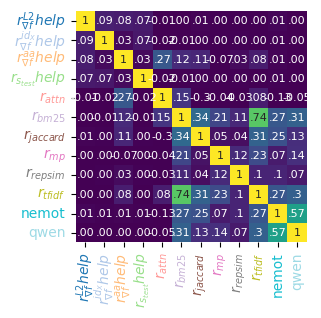

In [4]:
for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    print(selection_strategy)
    plot_mds_and_heatmaps(
        df,
        row_cols=["score_name", "k", "normalize"],
        col_col=None,
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )
    # break

most_influential
experiment_score_name=cka_k=-1_normalize=false


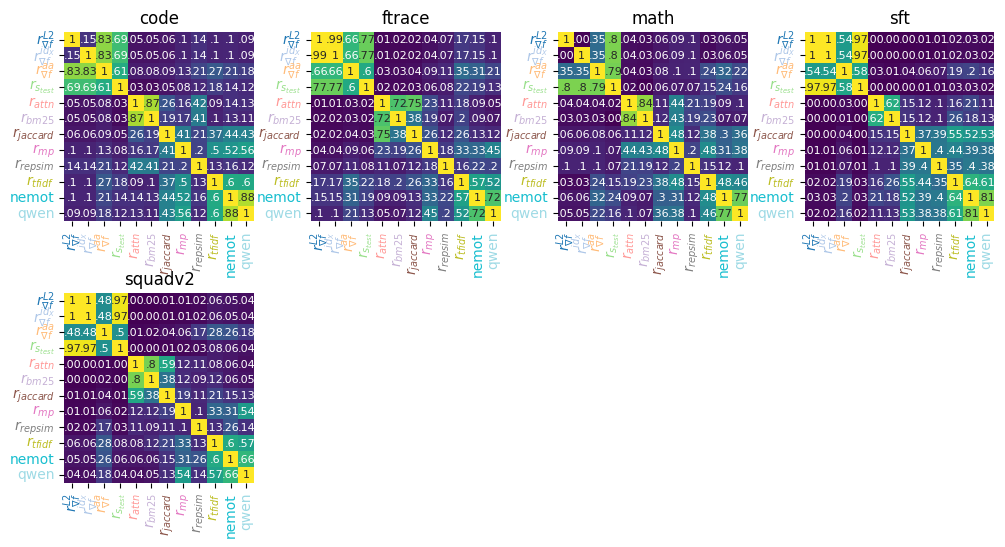

experiment_score_name=pw_acc_k=-1_normalize=false


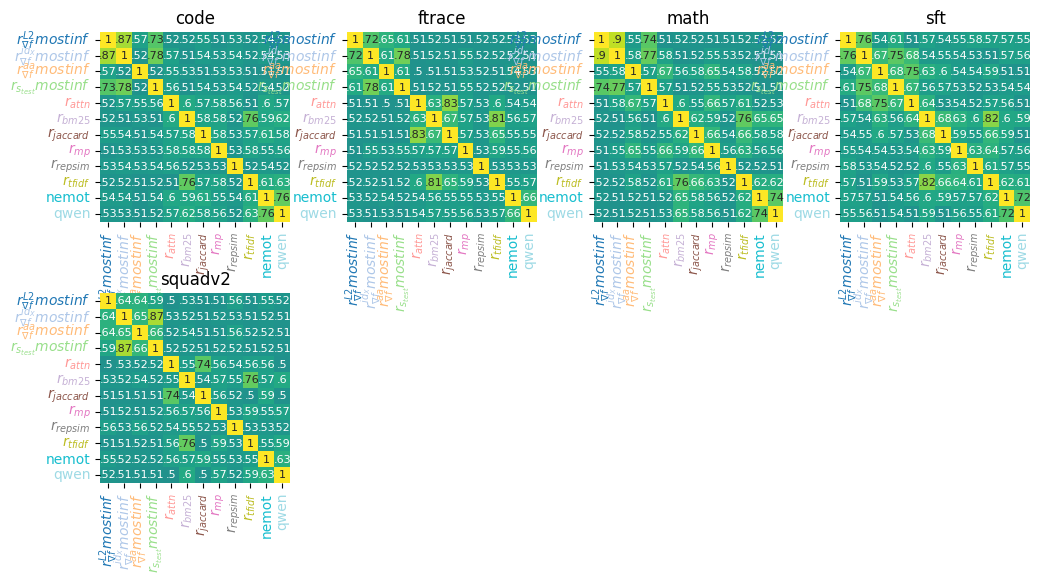

experiment_score_name=spearman_rho_k=-1_normalize=false


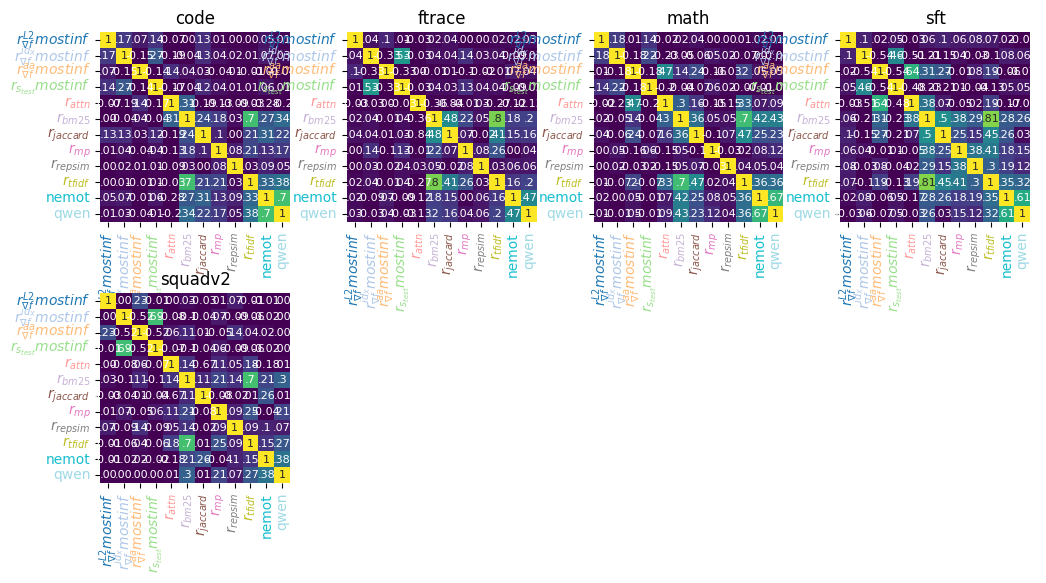

In [5]:
for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    print(selection_strategy)
    plot_mds_and_heatmaps(
        df,
        row_cols=["score_name", "k", "normalize"],
        col_col="Experiment",
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )
    break

most_influential
base_model_score_name=cka_k=-1_normalize=false


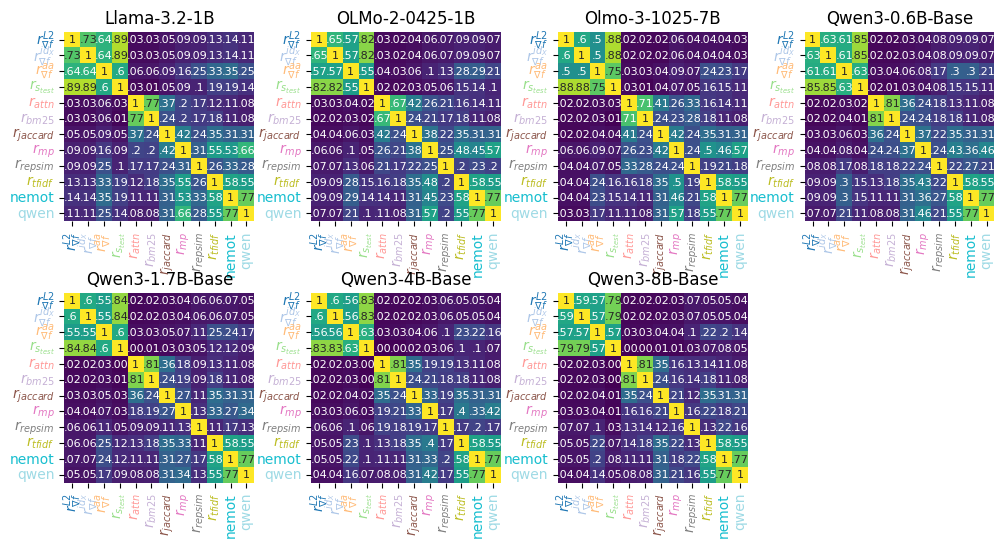

base_model_score_name=pw_acc_k=-1_normalize=false


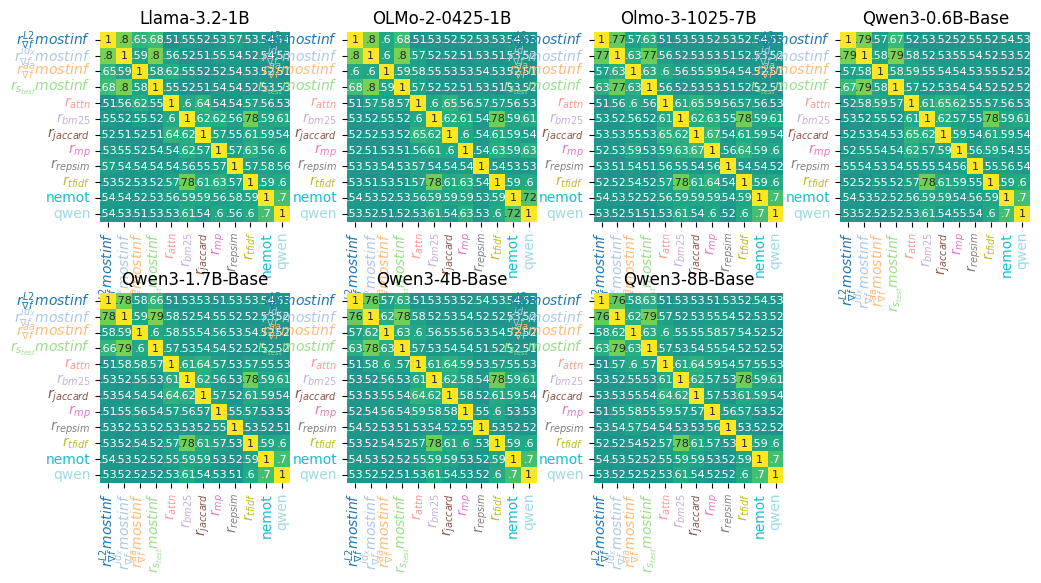

base_model_score_name=spearman_rho_k=-1_normalize=false


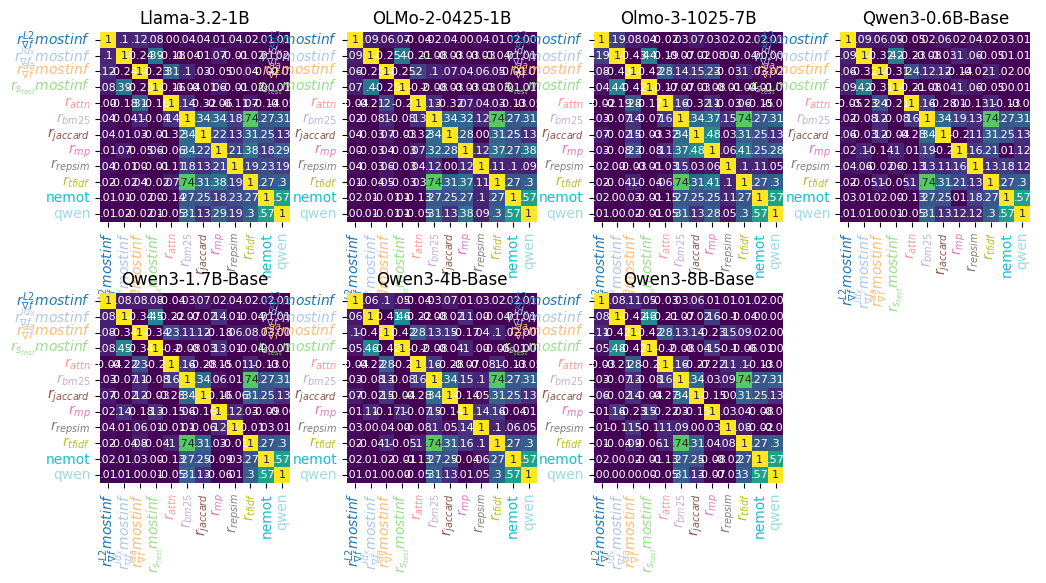

In [6]:
for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    print(selection_strategy)
    plot_mds_and_heatmaps(
        df,
        row_cols=["score_name", "k", "normalize"],
        col_col="base_model",
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )
    break